In [ ]:
# Environnement : en local, lancer le notebook depuis la racine du depot.
# Sur Google Colab, on clone le depot puis on se place dedans.
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('models'):
    os.system('git clone https://github.com/AISSAOUI-15/generative-image-reconstruction.git')
    os.chdir('generative-image-reconstruction')

In [ ]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '3'

import numpy as np
from models import *

import torch
import torch.optim

#from skimage.measure import compare_psnr
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import mean_squared_error
from utils.denoising_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

imsize =-1
PLOT = True
sigma = 50
sigma_ = sigma/255.

In [ ]:
fname = 'data/denoising/F16_GT.png'

In [ ]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '3'

import numpy as np
from models import *

import torch
import torch.optim

#from skimage.measure import compare_psnr
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import mean_squared_error
from utils.denoising_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

imsize =-1
PLOT = True
sigma = 50
sigma_ = sigma/255.

In [ ]:
fname = 'data/denoising/F16_GT.png'

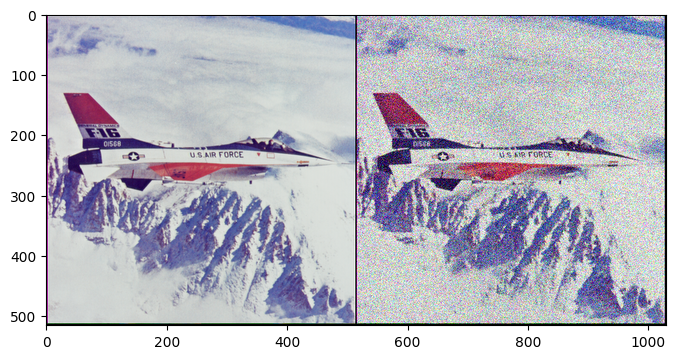

In [ ]:
fname == 'data/denoising/F16_GT.png'
# Add synthetic noise
img_pil = crop_image(get_image(fname, imsize)[0], d=32)
img_np = pil_to_np(img_pil)

img_noisy_pil, img_noisy_np = get_noisy_image(img_np, sigma_)

if PLOT:
    plot_image_grid([img_np, img_noisy_np], 4, 6);

In [ ]:
INPUT = 'noise' # 'meshgrid'     définie à 'noise'
pad = 'reflection'              # 'reflection', indiquant l'utilisation de la réflexion comme méthode de rembourrage.
OPT_OVER = 'net' # 'net,input'       l'optimisation sera effectuée sur le modèle de débruitage

reg_noise_std = 1./30. # set to 1./20. for sigma=50
LR = 0.01            # le taux d'apprentissage

OPTIMIZER='adam' # 'LBFGS'
show_every = 1000
exp_weight=0.99           #paramètre qui contrôle l'influence relative des itérations antérieures par rapport à la dernière itération lors de l'optimisation.



fname == 'data/denoising/F16_GT.png'
num_iter = 1500
input_depth = 32
figsize = 4


net = get_net(input_depth, 'skip', pad,
              skip_n33d=128,
              skip_n33u=128,
              skip_n11=4,
              num_scales=5,
              upsample_mode='bilinear').type(dtype)


net_input = get_noise(input_depth, INPUT, (img_pil.size[1], img_pil.size[0])).type(dtype).detach() # configurée pour contenir du bruit

# Compute number of parameters
s  = sum([np.prod(list(p.size())) for p in net.parameters()]);
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)

img_noisy_torch = np_to_torch(img_noisy_np).type(dtype)



Number of params: 2217831


Starting optimization with ADAM


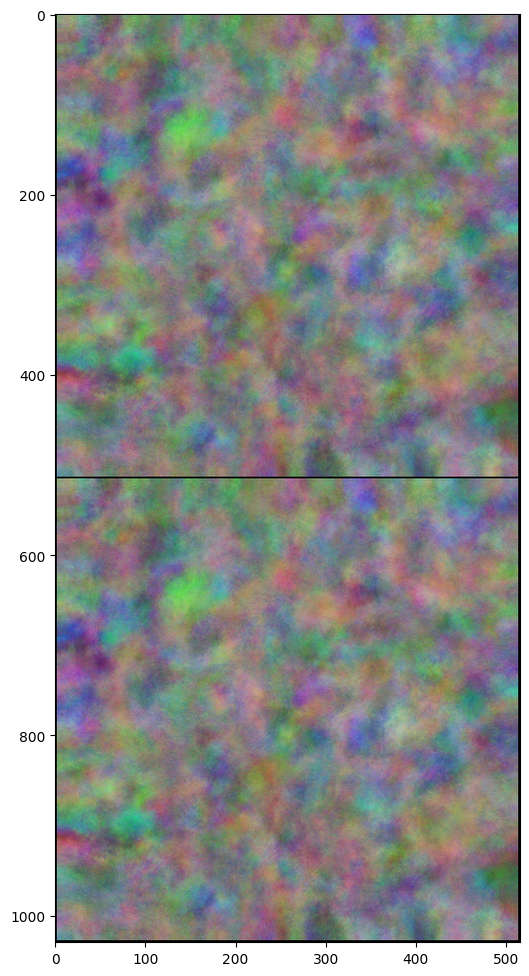

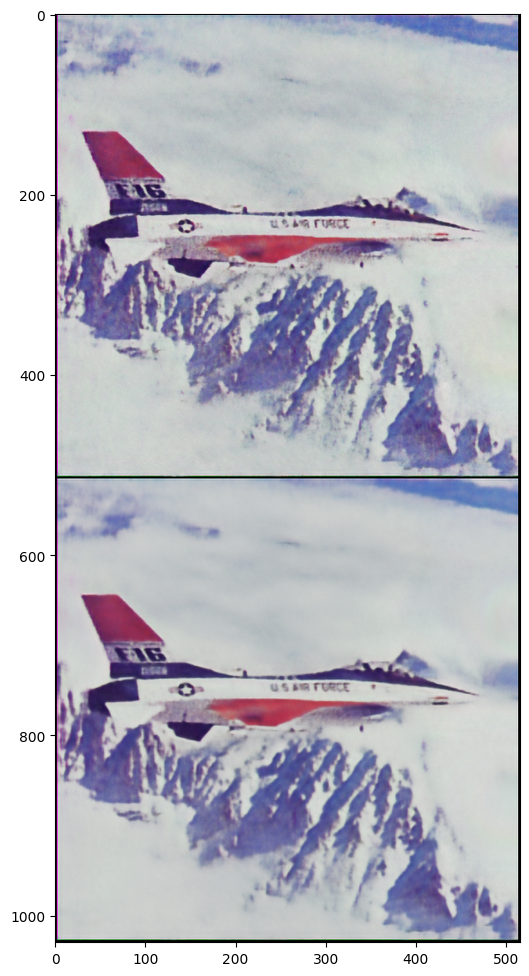

In [ ]:
from skimage.metrics import mean_squared_error
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device)

net_input_saved = net_input.detach().clone()    # copies détachées de l'entrée du modèle
noise = net_input.detach().clone()              # net_input_saved est utilisé pour sauvegarder l'entrée originale, et noise est utilisé pour ajouter du bruit à l'entrée pendant l'optimisation.
out_avg = None                                  # variable qui stocke la moyenne exponentielle mobile des sorties du modèle.
last_net = None
psrn_noisy_last = 0
Iter_loss = []

i = 0
def closure():         # Cette fonction est appelée à chaque itération de l'optimisation

    global i, out_avg, psrn_noisy_last, last_net, net_input

    if torch.cuda.is_available():
        net.cuda()

    if reg_noise_std > 0:          #  (l'écart-type du bruit régulier) est supérieur à 0, le bruit est ajouté à l'entrée du modèle.
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)

    out = net(net_input)

    # Smoothing
    if out_avg is None:
        out_avg = out.detach()
    else:
        out_avg = out_avg * exp_weight + out.detach() * (1 - exp_weight)

    total_loss = mse(out, img_noisy_torch)
    Iter_mse = mean_squared_error(out.detach().cpu().numpy()[0], img_np)
    Iter_loss.append(Iter_mse)
    total_loss.backward()        # La perte est rétropropagée à travers le réseau.


    psrn_noisy = peak_signal_noise_ratio(img_noisy_np, out.detach().cpu().numpy()[0])
    psrn_gt    = peak_signal_noise_ratio(img_np, out.detach().cpu().numpy()[0])
    psrn_gt_sm = peak_signal_noise_ratio(img_np, out_avg.detach().cpu().numpy()[0])

    # Note that we do not have GT for the "snail" example
    # So 'PSRN_gt', 'PSNR_gt_sm' make no sense
    print ('Iteration %05d    Loss %f   PSNR_noisy: %f   PSRN_gt: %f PSNR_gt_sm: %f' % (i, total_loss.item(), psrn_noisy, psrn_gt, psrn_gt_sm), '\r', end='')
    if  PLOT and i % show_every == 0:
        out_np = torch_to_np(out)
        plot_image_grid([np.clip(out_np, 0, 1),
                         np.clip(torch_to_np(out_avg), 0, 1)], factor=figsize, nrow=1)



    # Backtracking
    if i % show_every:
        if psrn_noisy - psrn_noisy_last < -5:
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.data.copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.detach().cpu() for x in net.parameters()]
            psrn_noisy_last = psrn_noisy

    i += 1

    return total_loss                 # La perte totale est calculée en utilisant la perte quadratique moyenne (mse) entre la sortie du modèle et l'image bruitée d'origine.

p = get_params(OPT_OVER, net, net_input)   #  récupère les paramètres du modèle en fonction de la méthode d'optimisation choisie (OPT_OVER).
optimize(OPTIMIZER, p, closure, LR, num_iter)   #  effectuer l'optimisation en utilisant l'optimiseur spécifié (OPTIMIZER) avec le taux d'apprentissage (LR) sur un certain nombre d'itérations (num_iter).

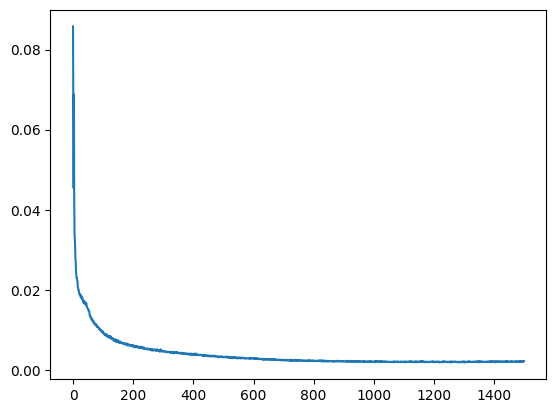

In [ ]:
plt.plot(Iter_loss)

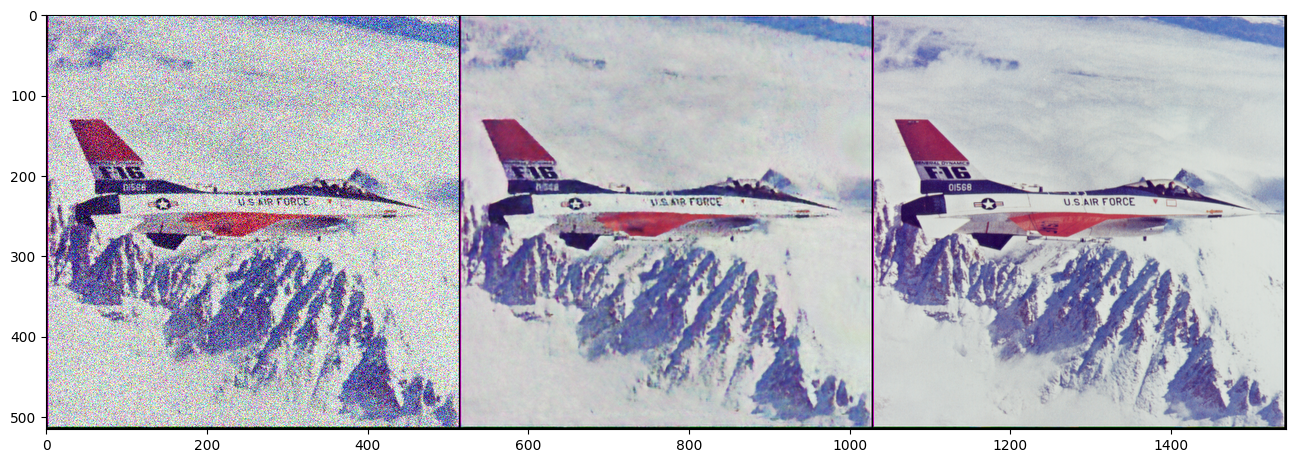

In [ ]:
out_np = torch_to_np(net(net_input))
q = plot_image_grid([img_noisy_np,np.clip(out_np, 0, 1), img_np], factor=13);

In [ ]:
from skimage.metrics import structural_similarity as ssim
# Initialiser une liste pour stocker les valeurs SSIM pour chaque canal
ssim_values = []

# Calculer SSIM pour chaque canal
for i in range(img_np.shape[0]):
    ssim_channel = ssim(img_np[i], out_np[i], data_range=out_np.max() - out_np.min())
    ssim_values.append(ssim_channel)

# Calculer la moyenne des valeurs SSIM pour chaque canal
ssim_mean = np.mean(ssim_values)

print("SSIM moyen  :", ssim_mean)

SSIM moyen  : 0.7283908087402713


In [ ]:
img_np = img_np.squeeze()
out_np = out_np.squeeze()
mse = np.mean((img_np - out_np) ** 2)
mse

0.0019877066